# سِبرَوان | Sibrawan - Mashael Alotaibi
Monthly **confirmed phishing incidents**, synthetic January 2020-December 2025.
Confirmed incident does **not** necessarily mean a successful compromise.
Goal: plan response capacity for the next quarter. This experiment cannot establish real-attack forecasting ability.
The original brief/rubric are preserved. Sections A-E follow their spine; the permitted data/framework/horizon adaptations are documented.


In [1]:
import sys, subprocess, os
from pathlib import Path
if 'google.colab' in sys.modules:
    repo = Path('/content/sibrawan')
    if not repo.exists():
        subprocess.run(['git','clone','https://github.com/mashaellna77-maker/Sibrawan.git',str(repo)], check=True)
    os.chdir(repo)
    subprocess.run([sys.executable,'-m','pip','install','-q','-r','requirements.txt'],check=True)
import time, json, hashlib
started=time.perf_counter()
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import acf
from statsmodels.graphics.tsaplots import plot_acf
from sibrawan import NAMES, forecast, rolling, score, residual_read
from coursekit import scoring
plt.rcParams.update({'figure.figsize':(10,4),'axes.spines.top':False,'axes.spines.right':False})
out=Path('artifacts'); out.mkdir(exist_ok=True)
def save(name):
    plt.tight_layout(); plt.savefig(out/f'{name}.png',dpi=160,bbox_inches='tight'); plt.show()
print('Python',sys.version.split()[0])


C:\Users\MashaelAlotaibi\Documents\Codex\2026-10-14\capstone-fork-https-github-com-mashaellna77\work\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python 3.12.14


## 0. Frozen synthetic data and visible conversion
`generate_data.py`, seed **20261014**, defines a gradual linear increase, a fixed 12-month seasonal profile, Gaussian noise, and four isolated positive shocks. These are assumptions, not empirical cybersecurity facts. The CSV is committed before fitting; re-execution checks its identity against the generator and never rewrites it to favor a model. No real organization or personal data are used.

In [2]:
from generate_data import generate, SEED
raw=pd.read_csv('data/synthetic_phishing.csv')
pd.testing.assert_frame_equal(raw,generate())
assert list(raw.columns)==['month','confirmed_phishing_incidents']
dates=pd.to_datetime(raw['month'],format='%Y-%m',errors='raise')
expected=pd.date_range('2020-01-01','2025-12-01',freq='MS')
assert len(raw)==72 and dates.nunique()==72
assert dates.is_monotonic_increasing and np.array_equal(dates.to_numpy(),expected.to_numpy())
assert not raw.isna().any().any()
assert pd.api.types.is_integer_dtype(raw.confirmed_phishing_incidents)
assert (raw.confirmed_phishing_incidents>=0).all()
# Equivalent to manual AutoGluon item_id/timestamp/target conversion:
# StatsForecast consumes visible long-format unique_id/ds/y directly.
df=pd.DataFrame({'unique_id':'Sibrawan synthetic phishing',
                 'ds':dates,'y':raw.confirmed_phishing_incidents.astype(float)})
data_sha=hashlib.sha256(Path('data/synthetic_phishing.csv').read_bytes()).hexdigest()
print('72 months; Jan 2020-Dec 2025; zero missing months, duplicates or nulls. Seed:',SEED)
print('CSV SHA256:',data_sha)
display(df.head())


72 months; Jan 2020-Dec 2025; zero missing months, duplicates or nulls. Seed: 20261014
CSV SHA256: 240acf974b7111616db5559ae0a56d5ac2efefbf20013a28d83298a3f732b026


,unique_id,ds,y
0,Sibrawan synthetic phishing,2020-01-01,52.0
1,Sibrawan synthetic phishing,2020-02-01,62.0
2,Sibrawan synthetic phishing,2020-03-01,62.0
3,Sibrawan synthetic phishing,2020-04-01,86.0
4,Sibrawan synthetic phishing,2020-05-01,66.0


## A. Exploration and shape

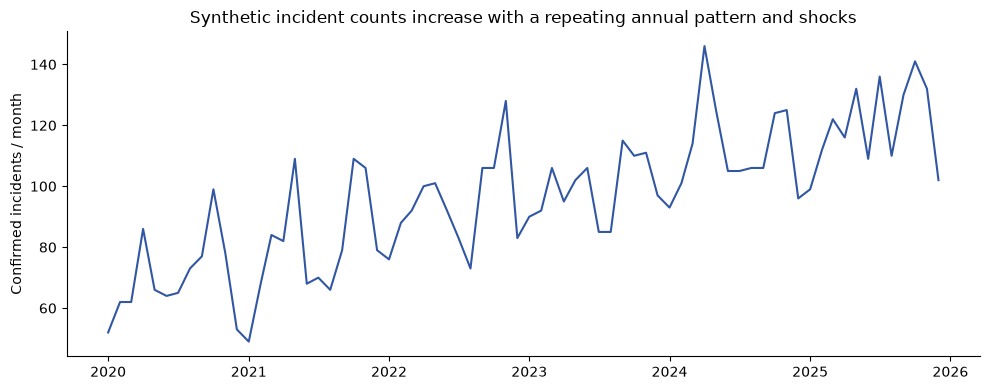

ds
2020     69.750000
2021     80.750000
2022     94.000000
2023     99.500000
2024    112.166667
2025    120.083333
Name: annual mean, dtype: float64

The annual average rises from **69.8** in 2020 to **120.1** in 2025. Within-year rises and falls recur, but isolated peaks exceed that pattern. These are generator assumptions; the raw plot alone does not distinguish seasonality from trend.

In [3]:
plt.plot(df.ds,df.y,color='#3157a4')
plt.title('Synthetic incident counts increase with a repeating annual pattern and shocks')
plt.ylabel('Confirmed incidents / month'); save('series')
annual=df.groupby(df.ds.dt.year).y.mean()
display(annual.rename('annual mean'))
display(Markdown(f'The annual average rises from **{annual.iloc[0]:.1f}** in 2020 to **{annual.iloc[-1]:.1f}** in 2025. Within-year rises and falls recur, but isolated peaks exceed that pattern. These are generator assumptions; the raw plot alone does not distinguish seasonality from trend.'))


<>:10: SyntaxWarning: invalid escape sequence '\m'
<>:10: SyntaxWarning: invalid escape sequence '\m'
<>:10: SyntaxWarning: invalid escape sequence '\m'
<>:10: SyntaxWarning: invalid escape sequence '\m'
<>:10: SyntaxWarning: invalid escape sequence '\m'
<>:10: SyntaxWarning: invalid escape sequence '\m'
<>:10: SyntaxWarning: invalid escape sequence '\m'
<>:10: SyntaxWarning: invalid escape sequence '\m'
C:\Users\MASHAE~1\AppData\Local\Temp\ipykernel_35768\3397065511.py:10: SyntaxWarning: invalid escape sequence '\m'
  display(Markdown(f'Textbook formulas: $F_T=\max(0,1-\mathrm{{Var}}(R)/\mathrm{{Var}}(T+R))$, $F_S=\max(0,1-\mathrm{{Var}}(R)/\mathrm{{Var}}(S+R))$. Trend spans {stl.trend.min():.1f} to {stl.trend.max():.1f} incidents; seasonal peak-to-trough is {np.ptp(stl.seasonal):.1f}; largest absolute remainder is {np.max(np.abs(stl.resid)):.1f}. The trend carries the long-run rise, seasonality the recurring within-year variation, and remainder the shocks/noise. Strengths motivate se

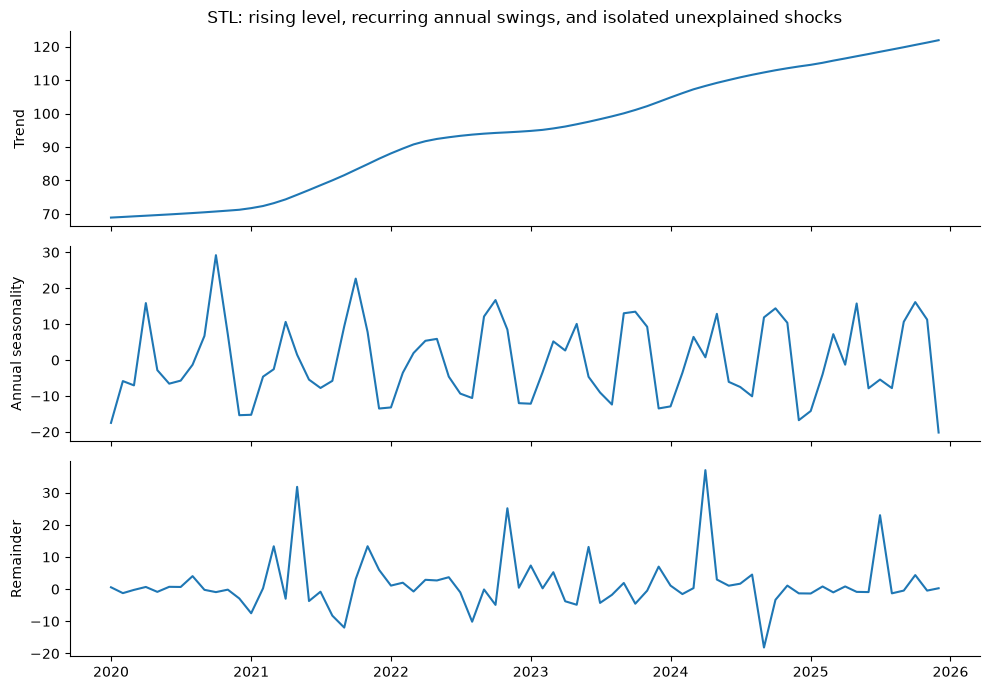

Trend strength = 0.8102; seasonal strength = 0.6188


Textbook formulas: $F_T=\max(0,1-\mathrm{Var}(R)/\mathrm{Var}(T+R))$, $F_S=\max(0,1-\mathrm{Var}(R)/\mathrm{Var}(S+R))$. Trend spans 68.9 to 121.9 incidents; seasonal peak-to-trough is 49.4; largest absolute remainder is 37.0. The trend carries the long-run rise, seasonality the recurring within-year variation, and remainder the shocks/noise. Strengths motivate seasonal and trend-aware candidates (ETS, ARIMA, Theta) alongside the seasonal floor. This full-series descriptive decomposition is never used to fit a fold.

In [4]:
stl=STL(df.y.to_numpy(),period=12,robust=True).fit()
fig,axs=plt.subplots(3,1,figsize=(10,7),sharex=True)
for ax,values,label in zip(axs,[stl.trend,stl.seasonal,stl.resid],['Trend','Annual seasonality','Remainder']):
    ax.plot(df.ds,values); ax.set_ylabel(label)
axs[0].set_title('STL: rising level, recurring annual swings, and isolated unexplained shocks')
save('stl')
trend_strength=max(0,1-np.var(stl.resid)/np.var(stl.trend+stl.resid))
seasonal_strength=max(0,1-np.var(stl.resid)/np.var(stl.seasonal+stl.resid))
print(f'Trend strength = {trend_strength:.4f}; seasonal strength = {seasonal_strength:.4f}')
display(Markdown(f'Textbook formulas: $F_T=\max(0,1-\mathrm{{Var}}(R)/\mathrm{{Var}}(T+R))$, $F_S=\max(0,1-\mathrm{{Var}}(R)/\mathrm{{Var}}(S+R))$. Trend spans {stl.trend.min():.1f} to {stl.trend.max():.1f} incidents; seasonal peak-to-trough is {np.ptp(stl.seasonal):.1f}; largest absolute remainder is {np.max(np.abs(stl.resid)):.1f}. The trend carries the long-run rise, seasonality the recurring within-year variation, and remainder the shocks/noise. Strengths motivate seasonal and trend-aware candidates (ETS, ARIMA, Theta) alongside the seasonal floor. This full-series descriptive decomposition is never used to fit a fold.'))


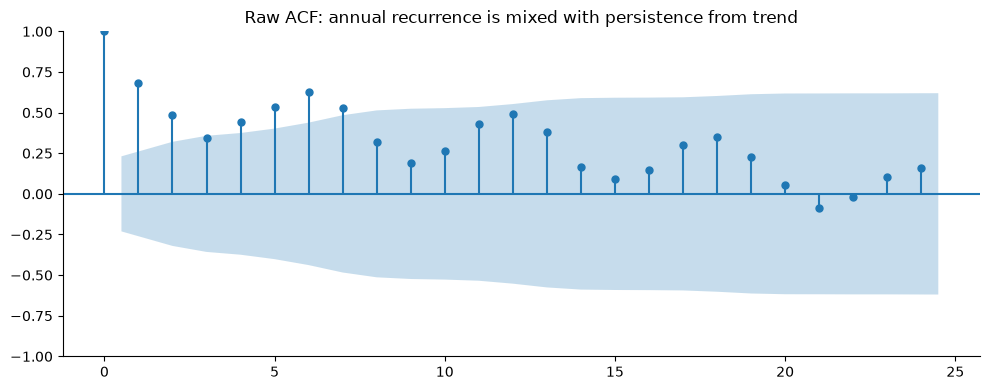

Raw ACF: lag 1 **0.679**, lag 12 **0.494**, lag 24 **0.157**. Positive annual-lag correlation means months one/two years apart tend to move together. It supports considering annual seasonality but does not isolate it: the rising level also produces correlation; higher-lag estimates use fewer pairs.

Approximate reference +/-0.231: lag 12 is stronger than lag 24; lag 24 alone is weak evidence of annual repetition in this finite raw series.


In [5]:
raw_acf=acf(df.y,nlags=24,fft=False)
plot_acf(df.y,lags=24); plt.title('Raw ACF: annual recurrence is mixed with persistence from trend'); save('raw_acf')
display(Markdown(f'Raw ACF: lag 1 **{raw_acf[1]:.3f}**, lag 12 **{raw_acf[12]:.3f}**, lag 24 **{raw_acf[24]:.3f}**. Positive annual-lag correlation means months one/two years apart tend to move together. It supports considering annual seasonality but does not isolate it: the rising level also produces correlation; higher-lag estimates use fewer pairs.'))
print(f'Approximate reference +/-{1.96/np.sqrt(len(df)):.3f}: lag 12 is stronger than lag 24; lag 24 alone is weak evidence of annual repetition in this finite raw series.')


## B. The floor and its remaining structure
The annual floor repeats the same month last year. Naive repeats the latest month. All five models receive native StatsForecast prediction intervals (levels 20,40,60,80,95) from the training data only; no post-hoc calibration against test outcomes. SeasonalNaive uses seasonal-difference residual RMS and a Gaussian prediction distribution; within h=3 its horizon factor is one. Distribution assumptions can fail under shocks or trend. Intervals are retained as continuous values, including any negative lower bound, for honest scoring; we do not silently clip them after evaluation.

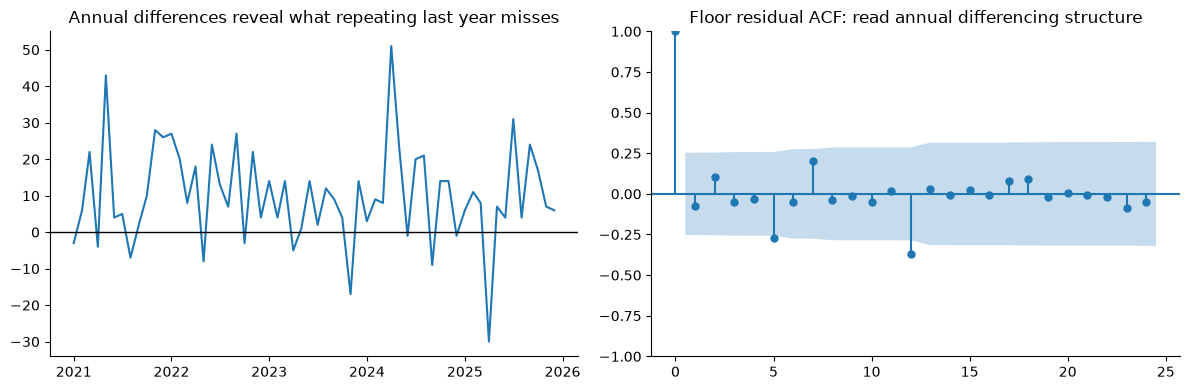

mean=10.07 (under-predicts on average), ACF(1)=-0.073, ACF(12)=-0.370; descriptive 95% reference +/-0.253; lag 1 is inside the approximate reference; lag 12 is outside the approximate reference


The residual mean indicates systematic under/over-prediction (positive means under-prediction). Compare the printed lag-1 and lag-12 values to the descriptive reference: values inside it are not persuasive evidence of remaining autocorrelation. Annual differencing can itself induce negative lag-12 correlation. Trend-aware models can address mean bias; shocks remain unpredictable without drivers. ACF bands are approximate diagnostics, not proof of independent errors.

In this run the floor leaves mean annual growth of **10.07 incidents**. Its lag-1 correlation is weak; the negative lag-12 correlation is outside the approximate reference and is consistent with annual differencing of shocks/noise. Repeating last year misses the rising level; trend-aware ETS/ARIMA are plausible candidates, not guaranteed winners.

,ds,y,SeasonalNaive,SeasonalNaive-lo-80,SeasonalNaive-hi-80,Naive
0,2024-01-01,93.0,90.0,69.713264,110.286736,97.0
1,2024-02-01,101.0,92.0,71.713264,112.286736,97.0
2,2024-03-01,114.0,106.0,85.713264,126.286736,97.0


In [6]:
resid_floor=df.y.diff(12).dropna()
fig,axs=plt.subplots(1,2,figsize=(12,4))
axs[0].plot(df.ds.iloc[12:],resid_floor); axs[0].axhline(0,color='black',lw=1)
axs[0].set_title('Annual differences reveal what repeating last year misses')
plot_acf(resid_floor,lags=24,ax=axs[1]); axs[1].set_title('Floor residual ACF: read annual differencing structure')
save('floor_residuals')
floor_read=residual_read(resid_floor)
print(floor_read)
display(Markdown('The residual mean indicates systematic under/over-prediction (positive means under-prediction). Compare the printed lag-1 and lag-12 values to the descriptive reference: values inside it are not persuasive evidence of remaining autocorrelation. Annual differencing can itself induce negative lag-12 correlation. Trend-aware models can address mean bias; shocks remain unpredictable without drivers. ACF bands are approximate diagnostics, not proof of independent errors.'))
display(Markdown(f'In this run the floor leaves mean annual growth of **{resid_floor.mean():.2f} incidents**. Its lag-1 correlation is weak; the negative lag-12 correlation is outside the approximate reference and is consistent with annual differencing of shocks/noise. Repeating last year misses the rising level; trend-aware ETS/ARIMA are plausible candidates, not guaranteed winners.'))
floor_preview=forecast(df.iloc[:48]).merge(df.iloc[48:51],on=['unique_id','ds'])
display(floor_preview[['ds','y','SeasonalNaive','SeasonalNaive-lo-80','SeasonalNaive-hi-80','Naive']])


## C. Framework and held-out leaderboard
**Documented alternative:** StatsForecast instead of AutoGluon. AutoGluon is not installed in this runtime; it adds large neural dependencies unnecessary for five classical models on 72 observations. The brief explicitly permits this alternative. No skipped or fabricated AutoGluon results are claimed. Manual conversion appears in section 0.

The zoo is actually fitted: Naive, SeasonalNaive(12), AutoETS(12), seasonal AutoARIMA (bounded stepwise search), AutoTheta(12). ETS/ARIMA choose structure on each training history; Theta estimates its variant and smoothing parameters. We keep the same fixed candidate set in all outer folds, rather than using a late leaderboard to shortlist earlier folds.

The equivalent internal evaluation is explicitly **two expanding windows** in the first 69 months: origins 63 and 66, h=3; the last three months are held out. `score_val=-mean internal MASE` and `score_test=-held-out MASE` below are our transparent adapter fields, not AutoGluon fields. Higher/less negative is better. Internal and test scores refer to different periods. This one held-out ranking is descriptive and cannot establish a reliable model winner; section D is the main evidence.

In [7]:
internal=[]
for n_train in [63,66]:
    hist=df.iloc[:n_train]
    val=forecast(hist).merge(df.iloc[n_train:n_train+3],on=['unique_id','ds'])
    for name in NAMES: internal.append({'model':name,'MASE':score(val,name,hist)['MASE']})
internal_scores=pd.DataFrame(internal).groupby('model').MASE.mean()
heldout=forecast(df.iloc[:69]).merge(df.iloc[69:],on=['unique_id','ds'])
leaderboard=pd.DataFrame([{'model':name,'score_val':-internal_scores[name],
    'score_test':-score(heldout,name,df.iloc[:69])['MASE'],'internal_windows':2} for name in NAMES]).sort_values('score_test',ascending=False)
display(leaderboard)
leaderboard.to_csv(out/'leaderboard.csv',index=False)


,model,score_val,score_test,internal_windows
2,AutoETS,-0.695996,-0.526532,2
4,AutoTheta,-0.859120,-0.672919,2
1,SeasonalNaive,-1.304605,-0.760000,2
3,AutoARIMA,-0.768718,-0.853017,2
0,Naive,-1.017436,-1.038667,2


## D. Rolling-origin harness - quarterly capacity planning
**8 windows, h=3, step=3, expanding training; first training has 48 months.** This matches planning for the next quarter; the brief/rubric permit adapting h/step. Every candidate uses exactly these origins. The future target is never used in fitting, tuning, interval generation or scaling. All data transformations for models are fitted internally on each history. Original `coursekit/scoring.py` was read: its interval ladder, quantile mapping and coverage are reused. Its MASE matches seasonal training scaling; its CRPS scale uses evaluation actuals, so we replace that scale to satisfy training-only denominators.

For each fold $d=\mathrm{mean}|y_t-y_{t-12}|$ over training only. MASE = test MAE/d. Approximate CRPS = twice the trapezoidal integral of quantile pinball loss at .025,.1,.2,.3,.4,.6,.7,.8,.9,.975, with zero endpoint losses at 0 and 1; scaled CRPS = CRPS/d. Sparse tails and zero endpoint assumptions make this a finite-grid approximation, not exact continuous CRPS or utilsforecast's evaluation-normalized score. Equal averages over folds; 80% coverage is the fraction of actuals within q.1-q.9; width is their average separation in incident units.

**Selection rule declared before seeing outer scores:** choose lowest mean scaled CRPS among models with coverage at least 80%; if none qualifies choose closest coverage to 80%, breaking ties by scaled CRPS. This is a retrospective final-deployment decision, not an unbiased performance estimate of the selected model. Report every candidate. A separate prequential adaptive policy below chooses only from completed previous folds, starting with SeasonalNaive, to show selection without future leakage.

In [8]:
cv,fold_scores,fold_dates=rolling(df)
assert list(fold_dates.n_train)==list(range(48,72,3))
assert len(cv)==24 and cv.ds.nunique()==24
display(fold_dates)
RESULTS=fold_scores.groupby('model')[['MASE','scaled_CRPS','coverage_80','width_80']].mean()
RESULTS['MASE_min']=fold_scores.groupby('model').MASE.min()
RESULTS['MASE_max']=fold_scores.groupby('model').MASE.max()
display(RESULTS.sort_values('scaled_CRPS'))
cv.to_csv(out/'cv_predictions.csv',index=False)
fold_scores.to_csv(out/'fold_scores.csv',index=False)
fold_dates.to_csv(out/'fold_dates.csv',index=False)
RESULTS.to_csv(out/'metrics.csv')
floor=RESULTS.loc['SeasonalNaive']
comparisons=[]
for name,row in RESULTS.iterrows():
    if name=='SeasonalNaive': continue
    x=fold_scores[fold_scores.model==name].set_index('fold')
    b=fold_scores[fold_scores.model=='SeasonalNaive'].set_index('fold')
    wins=list(x.index[x.MASE<b.MASE]); losses=list(x.index[x.MASE>b.MASE])
    crps_wins=list(x.index[x.scaled_CRPS<b.scaled_CRPS]); crps_losses=list(x.index[x.scaled_CRPS>b.scaled_CRPS])
    text=(f'{name}: MASE {row.MASE:.3f} vs floor {floor.MASE:.3f} ({"wins" if row.MASE<floor.MASE else "loses"}); '
          f'scaled CRPS {row.scaled_CRPS:.3f} vs {floor.scaled_CRPS:.3f} ({"wins" if row.scaled_CRPS<floor.scaled_CRPS else "loses"}); '
          f'80% coverage {row.coverage_80:.1%}, width {row.width_80:.1f}; '
          f'point wins in folds {wins}, losses {losses}; distribution wins {crps_wins}, losses {crps_losses}.')
    comparisons.append(text); print(text)
print(f'Floor 80% coverage: {floor.coverage_80:.1%}; width {floor.width_80:.1f}.')
display(Markdown('Coverage verdict: below 80% is undercoverage; above 80% is conservative observed coverage. There are only 24 targets: one target changes coverage by 4.17 percentage points, and adjacent errors may depend on each other. Near nominal coverage does not certify calibration. Width must be read alongside coverage and CRPS, not rewarded for being small alone. See the fold table for time variation rather than treating one test split as final.'))


,fold,n_train,train_start,train_end,test_start,test_end
0,1,48,2020-01-01,2023-12-01,2024-01-01,2024-03-01
1,2,51,2020-01-01,2024-03-01,2024-04-01,2024-06-01
2,3,54,2020-01-01,2024-06-01,2024-07-01,2024-09-01
3,4,57,2020-01-01,2024-09-01,2024-10-01,2024-12-01
4,5,60,2020-01-01,2024-12-01,2025-01-01,2025-03-01
5,6,63,2020-01-01,2025-03-01,2025-04-01,2025-06-01
6,7,66,2020-01-01,2025-06-01,2025-07-01,2025-09-01
7,8,69,2020-01-01,2025-09-01,2025-10-01,2025-12-01


,MASE,scaled_CRPS,coverage_80,width_80,MASE_min,MASE_max
model,,,,,,
AutoETS,0.537812,0.435200,0.916667,31.253244,0.099996,0.991457
AutoARIMA,0.676643,0.506956,0.791667,28.843546,0.162149,1.355434
AutoTheta,0.772406,0.550424,0.833333,30.112596,0.234044,1.075625
Naive,0.945017,0.717303,0.916667,59.861103,0.051282,1.435244
SeasonalNaive,1.077918,0.767599,0.791667,42.371631,0.532151,2.070064


AutoARIMA: MASE 0.677 vs floor 1.078 (wins); scaled CRPS 0.507 vs 0.768 (wins); 80% coverage 79.2%, width 28.8; point wins in folds [1, 2, 3, 4, 5, 6, 7], losses [8]; distribution wins [1, 2, 3, 4, 5, 6, 7], losses [8].
AutoETS: MASE 0.538 vs floor 1.078 (wins); scaled CRPS 0.435 vs 0.768 (wins); 80% coverage 91.7%, width 31.3; point wins in folds [1, 2, 3, 4, 5, 6, 7, 8], losses []; distribution wins [1, 2, 3, 4, 5, 6, 7, 8], losses [].
AutoTheta: MASE 0.772 vs floor 1.078 (wins); scaled CRPS 0.550 vs 0.768 (wins); 80% coverage 83.3%, width 30.1; point wins in folds [1, 2, 3, 6, 7, 8], losses [4, 5]; distribution wins [1, 2, 3, 6, 7, 8], losses [4, 5].
Naive: MASE 0.945 vs floor 1.078 (wins); scaled CRPS 0.717 vs 0.768 (wins); 80% coverage 91.7%, width 59.9; point wins in folds [2, 3, 6, 7], losses [1, 4, 5, 8]; distribution wins [2, 3, 6, 7], losses [1, 4, 5, 8].
Floor 80% coverage: 79.2%; width 42.4.


Coverage verdict: below 80% is undercoverage; above 80% is conservative observed coverage. There are only 24 targets: one target changes coverage by 4.17 percentage points, and adjacent errors may depend on each other. Near nominal coverage does not certify calibration. Width must be read alongside coverage and CRPS, not rewarded for being small alone. See the fold table for time variation rather than treating one test split as final.

In [9]:
def select(table):
    eligible=table[table.coverage_80>=.8]
    if len(eligible): return eligible.sort_values('scaled_CRPS').index[0]
    return table.assign(distance=(table.coverage_80-.8).abs()).sort_values(['distance','scaled_CRPS']).index[0]
chosen=select(RESULTS)
policy=[]
for fold in range(1,9):
    past=fold_scores[fold_scores.fold<fold]
    pick='SeasonalNaive' if past.empty else select(past.groupby('model')[['scaled_CRPS','coverage_80']].mean())
    policy.append(fold_scores[(fold_scores.fold==fold)&(fold_scores.model==pick)].assign(selected_model=pick))
policy=pd.concat(policy)
display(policy[['fold','selected_model','MASE','scaled_CRPS','coverage_80','width_80']])
print('Prequential policy mean:',policy[['MASE','scaled_CRPS','coverage_80','width_80']].mean().to_dict())
print('Final retrospective choice:',chosen)
policy.to_csv(out/'prequential_policy.csv',index=False)
recommendation=f'Use {chosen} provisionally for synthetic next-quarter capacity planning: rolling scaled CRPS {RESULTS.loc[chosen,"scaled_CRPS"]:.3f}, with observed 80% coverage {RESULTS.loc[chosen,"coverage_80"]:.1%}.'
display(Markdown(recommendation))


,fold,selected_model,MASE,scaled_CRPS,coverage_80,width_80
1,1,SeasonalNaive,0.532151,0.385873,1.000000,40.573472
7,2,AutoETS,0.991457,0.783427,0.666667,24.655423
12,3,AutoETS,0.516100,0.392512,1.000000,31.971096
17,4,AutoETS,0.652357,0.393873,1.000000,35.152685
22,5,AutoETS,0.099996,0.233220,1.000000,31.265161
27,6,AutoETS,0.631108,0.470710,1.000000,34.590864
32,7,AutoETS,0.760884,0.637043,0.666667,31.175887
37,8,AutoETS,0.526532,0.374042,1.000000,35.501042


Prequential policy mean: {'MASE': 0.5888232302142389, 'scaled_CRPS': 0.45883750450564526, 'coverage_80': 0.9166666666666666, 'width_80': 33.110703621819695}
Final retrospective choice: AutoETS


Use AutoETS provisionally for synthetic next-quarter capacity planning: rolling scaled CRPS 0.435, with observed 80% coverage 91.7%.

## E. Residual evidence, managerial report and final forecast
Floor residuals above are in-sample annual differences. Below are **out-of-sample rolling forecast errors** for the floor and final candidate, different diagnostics. The 24 chronological errors mix horizons 1-3 across quarterly refits, so their ACF is exploratory and is not an innovations whiteness test. Selection uses this same evaluation and can be optimistic; prequential results are shown separately. No Ljung-Box requirement.

SeasonalNaive mean=10.29 (under-predicts on average), ACF(1)=0.001, ACF(12)=-0.318; descriptive 95% reference +/-0.400; lag 1 is inside the approximate reference; lag 12 is inside the approximate reference


AutoETS mean=-1.24 (over-predicts on average), ACF(1)=0.134, ACF(12)=-0.129; descriptive 95% reference +/-0.400; lag 1 is inside the approximate reference; lag 12 is inside the approximate reference


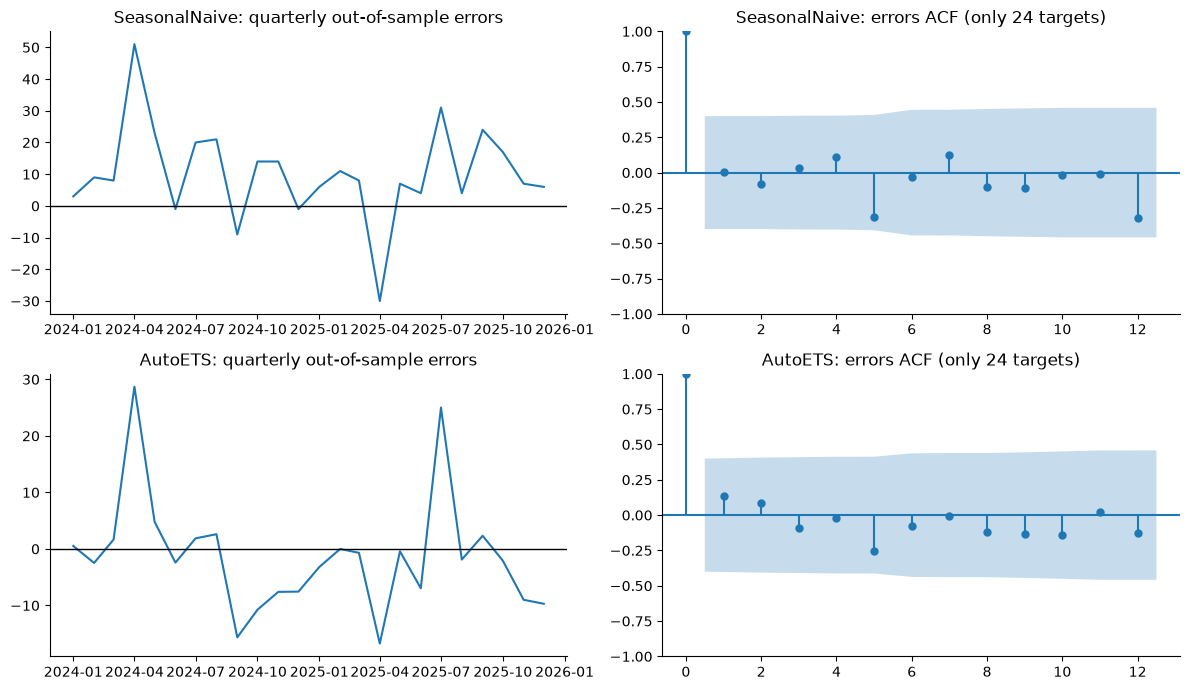

The proposed model has its largest absolute rolling error in **2024-04**: actual minus forecast **28.7** incidents. Its mean error is **-1.24**, versus **10.29** for the floor. The printed lag-1/lag-12 comparisons show whether low-lag or annual structure remains convincing in this small test sample; isolated surges remain a practical miss even when the ACF looks weak.

Positive error mean means missed demand; isolated large positive errors expose unexpected surges. ACF outside its printed reference suggests structure to investigate, while inside-band estimates cannot prove randomness. The next development step is to collect consistently defined, real monthly confirmed-incident counts plus monthly incoming suspicious-message volume, and compare a lagged-volume regression against this same quarterly floor using training-only joins. A workload driver may capture surges, but only a real-data backtest can test that claim.

In [10]:
fig,axs=plt.subplots(2,2,figsize=(12,7))
residual_text={}
for i,name in enumerate(['SeasonalNaive',chosen]):
    errors=cv.y-cv[name]
    axs[i,0].plot(cv.ds,errors); axs[i,0].axhline(0,color='black',lw=1)
    axs[i,0].set_title(f'{name}: quarterly out-of-sample errors')
    plot_acf(errors,lags=12,ax=axs[i,1]); axs[i,1].set_title(f'{name}: errors ACF (only 24 targets)')
    residual_text[name]=residual_read(errors)
    print(name,residual_text[name])
save('model_residuals')
proposed_errors=cv.y-cv[chosen]
largest=int(np.argmax(np.abs(proposed_errors)))
display(Markdown(f'The proposed model has its largest absolute rolling error in **{cv.ds.iloc[largest]:%Y-%m}**: actual minus forecast **{proposed_errors.iloc[largest]:.1f}** incidents. Its mean error is **{proposed_errors.mean():.2f}**, versus **{(cv.y-cv.SeasonalNaive).mean():.2f}** for the floor. The printed lag-1/lag-12 comparisons show whether low-lag or annual structure remains convincing in this small test sample; isolated surges remain a practical miss even when the ACF looks weak.'))
display(Markdown('Positive error mean means missed demand; isolated large positive errors expose unexpected surges. ACF outside its printed reference suggests structure to investigate, while inside-band estimates cannot prove randomness. The next development step is to collect consistently defined, real monthly confirmed-incident counts plus monthly incoming suspicious-message volume, and compare a lagged-volume regression against this same quarterly floor using training-only joins. A workload driver may capture surges, but only a real-data backtest can test that claim.'))


,month,mean,lo80,hi80,lo95,hi95
0,2026-01-01,111.386758,96.733979,126.039537,88.977267,133.796249
1,2026-02-01,121.666138,105.661121,137.671156,97.188576,146.143700
2,2026-03-01,130.837565,113.626059,148.049071,104.514837,157.160292


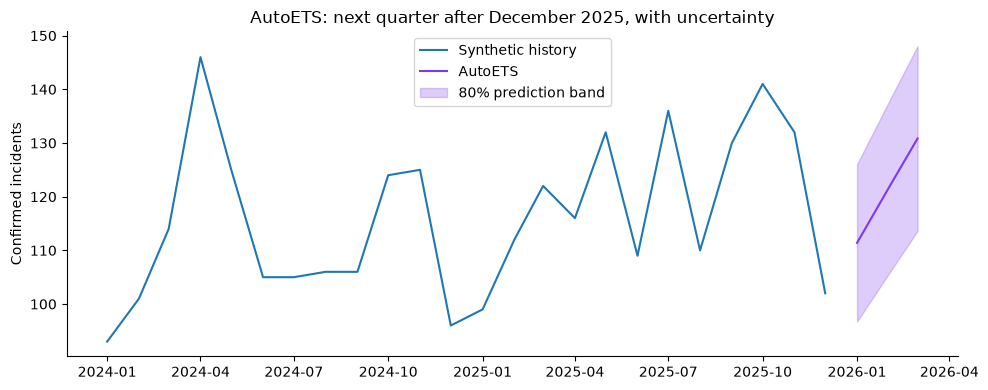

These are January-March 2026, the three months following the supplied history, not the three months after the submission date. Point forecasts are expected counts, hence may be fractional. Bands describe model uncertainty, not a guarantee or evidence of a successful breach. Capacity planning can use the upper 80% bound as a stress scenario, not an absolute maximum.

Analysis elapsed: 24.2s. Report regenerated from this run.


In [11]:
full_fc=forecast(df)
final=full_fc[['ds',chosen,f'{chosen}-lo-80',f'{chosen}-hi-80',f'{chosen}-lo-95',f'{chosen}-hi-95']].copy()
final.columns=['month','mean','lo80','hi80','lo95','hi95']
assert list(final.month.dt.strftime('%Y-%m'))==['2026-01','2026-02','2026-03']
display(final)
final.to_csv(out/'final_forecast.csv',index=False)
plt.plot(df.ds.iloc[-24:],df.y.iloc[-24:],label='Synthetic history')
plt.plot(final.month,final['mean'],label=chosen,color='#7c3aed')
plt.fill_between(final.month,final.lo80,final.hi80,alpha=.25,color='#7c3aed',label='80% prediction band')
plt.title(f'{chosen}: next quarter after December 2025, with uncertainty')
plt.ylabel('Confirmed incidents'); plt.legend(); save('final_forecast')
display(Markdown('These are January-March 2026, the three months following the supplied history, not the three months after the submission date. Point forecasts are expected counts, hence may be fractional. Bands describe model uncertainty, not a guarantee or evidence of a successful breach. Capacity planning can use the upper 80% bound as a stress scenario, not an absolute maximum.'))
summary={'chosen':chosen,'recommendation':recommendation,'data_sha256':data_sha,
         'trend_strength':trend_strength,'seasonal_strength':seasonal_strength,
         'acf12':float(raw_acf[12]),'acf24':float(raw_acf[24]),'floor_read':floor_read,
         'residuals':residual_text,'comparisons':comparisons,
         'runtime_seconds':time.perf_counter()-started}
(out/'summary.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
from report_builder import build_report
build_report(RESULTS,final,summary)
print(f'Analysis elapsed: {summary["runtime_seconds"]:.1f}s. Report regenerated from this run.')


### Sources and reproducibility
- [STL strength formulas, Forecasting: Principles and Practice](https://otexts.com/fpp3/feasts.html)
- [StatsForecast models](https://nixtlaverse.nixtla.io/statsforecast/src/core/models.html)
- [StatsForecast cross validation](https://nixtlaverse.nixtla.io/statsforecast/docs/tutorials/crossvalidation.html)
- Original `brief.md`, `rubric.md`, and `coursekit/scoring.py` remain in this fork.
Artifacts, report.md and PDF are produced only from executed cells. The Streamlit app reads these saved results without API credentials; optional Gemini is separate. Neither an interface nor a bot substitutes for this evaluation.
